In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# 22 - Governments and policy milestones against the data
Italian governments (dates from Wikipedia, English and Italian editions agree) and 46 laws, decrees and EU/ECB decisions from `data/external/italy_policies.csv`; each entry is labelled *verified* (confirmed in a source during this project), *partly verified* or *unverified* (see the file). Everything below is **descriptive timing, not causal attribution**: policies act with lags, several overlap, and the euro-area environment dominates some series.

In [2]:
from cifresignificative.studies.italy_productivity.analysis.timeline import load_governments, load_policies, government_stats
gov = load_governments("2001-01-01"); pol = load_policies(); lh = load_long()
print(len(pol), "policies:", pol.evidence.value_counts().to_dict())
stats = government_stats(lh, load_governments("1989-01-01"), "1989-01-01")
st = stats.dropna(subset=["gdp_growth_pa_italy", "gdp_growth_pa_others"]).copy()
slower = (st.gdp_growth_pa_italy < st.gdp_growth_pa_others).sum()
print(f"Italy grew more slowly than the median of the other members under {slower} of {len(st)} governments (weighted by time in office); faster under:", st[st.gdp_growth_pa_italy >= st.gdp_growth_pa_others].government.tolist())
show = stats[["government", "start", "months", "gdp_growth_pa_italy", "gdp_growth_pa_others", "unemployment_rate_italy", "unemployment_rate_others", "debt_change_pp_italy", "debt_change_pp_others"]].round(1)
display(show.set_index("government"))

46 policies: {'verified': 46}
Italy grew more slowly than the median of the other members under 21 of 22 governments (weighted by time in office); faster under: ['Draghi']


,start,months,gdp_growth_pa_italy,gdp_growth_pa_others,unemployment_rate_italy,unemployment_rate_others,debt_change_pp_italy,debt_change_pp_others
government,,,,,,,,
De Mita,1988-04-13,15.3,3.7,4.4,9.8,7.2,2.4,-2.1
Andreotti VI,1989-07-23,20.7,2.2,3.4,9.1,5.8,3.7,0.8
Andreotti VII,1991-04-13,14.5,1.1,1.7,8.7,5.9,5.5,14.3
Amato I,1992-06-28,10.0,0.1,0.6,9.4,7.7,6.4,13.6
Ciampi,1993-04-28,12.4,0.2,1.0,10.5,8.9,8.7,10.9
Berlusconi I,1994-05-11,8.2,2.1,3.0,11.0,9.1,3.9,1.2
Dini,1995-01-17,16.0,2.3,3.4,11.6,9.7,2.3,-0.9
Prodi I,1996-05-18,29.1,1.7,3.7,12.0,9.5,-4.6,-1.1
D'Alema I-II,1998-10-21,18.2,2.2,3.6,11.4,8.5,-2.7,0.4


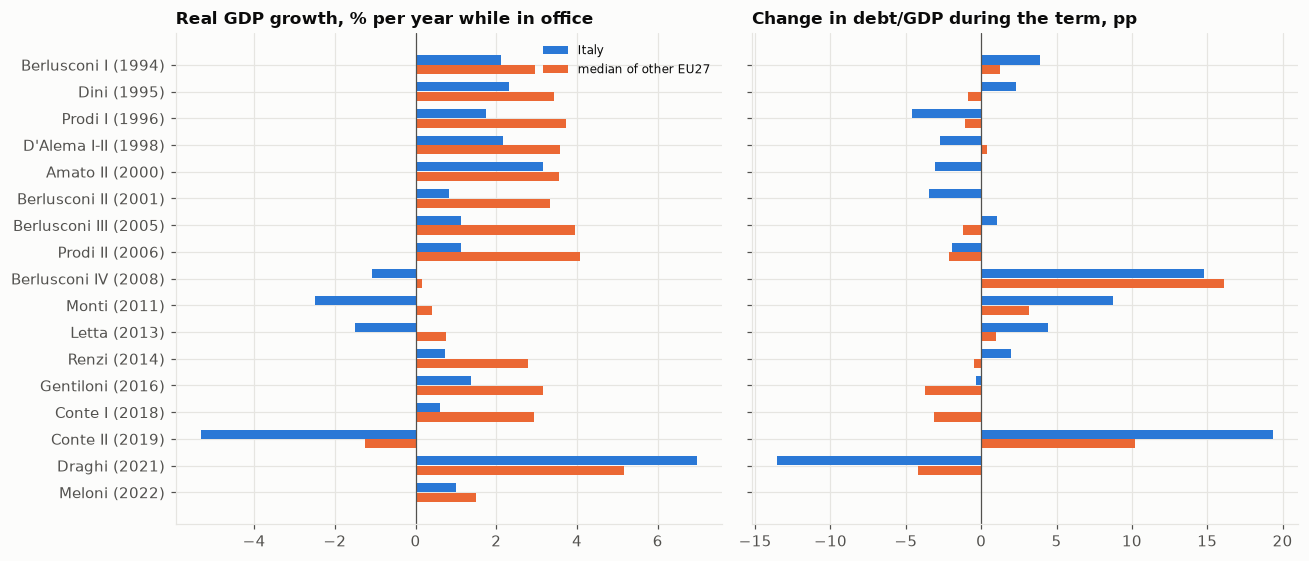

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
s = stats[stats.start >= pd.Timestamp("1994-01-01").date()].reset_index(drop=True); yy = np.arange(len(s))
axes[0].barh(yy - 0.18, s.gdp_growth_pa_italy, height=0.34, color=ITALY_C, label="Italy"); axes[0].barh(yy + 0.18, s.gdp_growth_pa_others, height=0.34, color=EU_C, label="median of other EU27")
axes[0].set_yticks(yy, [f"{g} ({st.year})" for g, st in zip(s.government, s.start, strict=True)]); axes[0].invert_yaxis(); axes[0].axvline(0, color=INK2, lw=0.8); axes[0].set_title("Real GDP growth, % per year while in office"); axes[0].legend(fontsize=8)
d = s.dropna(subset=["debt_change_pp_italy"]); axes[1].barh(np.arange(len(d)) - 0.18 + (len(s) - len(d)) * 0, d.debt_change_pp_italy, height=0.34, color=ITALY_C); axes[1].barh(np.arange(len(d)) + 0.18, d.debt_change_pp_others, height=0.34, color=EU_C)
axes[1].axvline(0, color=INK2, lw=0.8); axes[1].set_title("Change in debt/GDP during the term, pp"); fig.tight_layout(); save(fig, "22_government_stats")

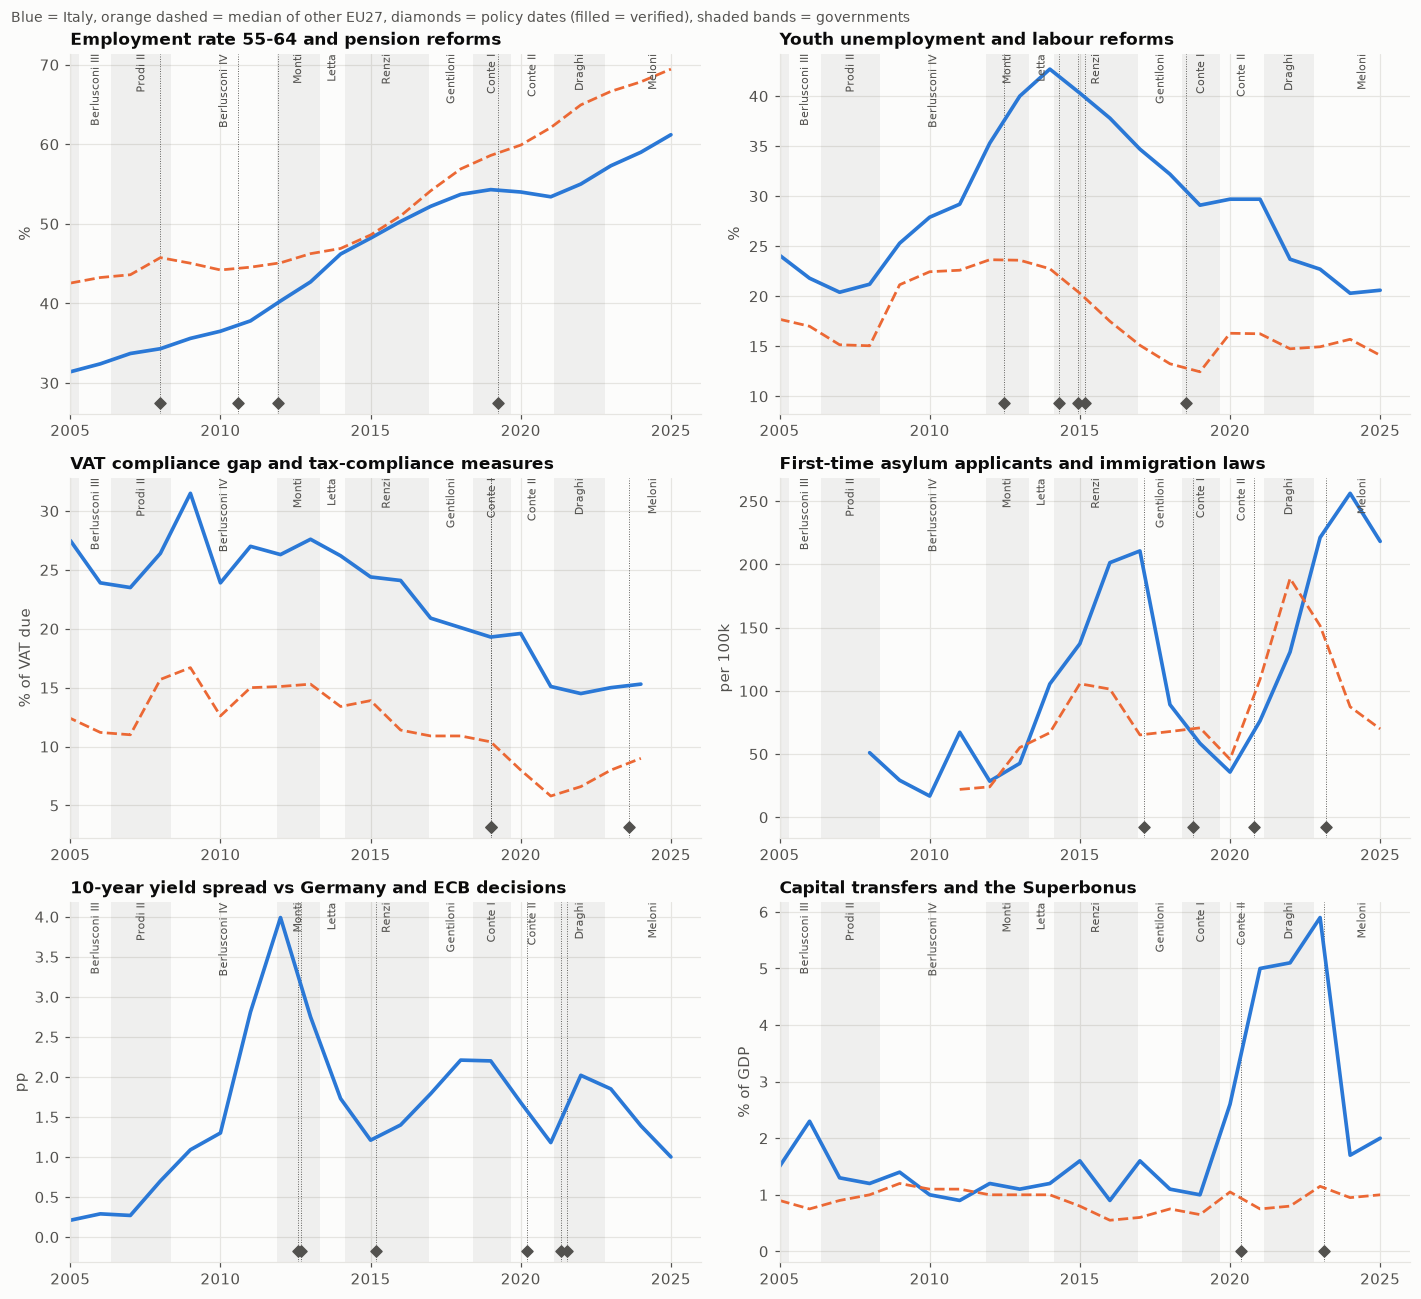

In [4]:
def panel_for(ax, series, title, ylabel, policies, xlim=(2005, 2025), median=None):
    ax.plot(series.index, series.values, color=ITALY_C, lw=2.4)
    if median is not None: ax.plot(median.index, median.values, color=EU_C, lw=1.8, ls="--")
    ax.set_title(title); ax.set_ylabel(ylabel); ax.set_xlim(xlim[0], xlim[1] + 1)
    lo, hi = ax.get_ylim(); ax.set_ylim(lo - 0.08 * (hi - lo), hi)
    draw_timeline(ax, gov, policies, xlim=xlim)
sel = lambda pat: pol[pol.domain.str.contains(pat, case=False)]
fig, axes = plt.subplots(3, 2, figsize=(13, 12))
w = wide(panel, "employment_rate_55_64"); panel_for(axes[0, 0], w[ITALY], "Employment rate 55-64 and pension reforms", "%", sel("pension"), median=eu_median_ex_italy(w))
w = wide(panel, "youth_unemployment_rate"); panel_for(axes[0, 1], w[ITALY], "Youth unemployment and labour reforms", "%", sel("labour"), median=eu_median_ex_italy(w))
w = wide(panel, "vat_compliance_gap_pct"); panel_for(axes[1, 0], w[ITALY].dropna(), "VAT compliance gap and tax-compliance measures", "% of VAT due", sel("tax"), median=eu_median_ex_italy(w).dropna())
w = wide(panel, "asylum_first_applicants_per_100k"); panel_for(axes[1, 1], w[ITALY].dropna(), "First-time asylum applicants and immigration laws", "per 100k", sel("immigration"), median=eu_median_ex_italy(w).dropna())
y = wide(panel, "long_term_yield"); spread = (y[ITALY] - y["DEU"]).dropna(); panel_for(axes[2, 0], spread, "10-year yield spread vs Germany and ECB decisions", "pp", sel("monetary|EU / inv|euro"))
sp = load_spending(); cap = spend_wide(sp, "D9PAY", "nature"); panel_for(axes[2, 1], cap[ITALY].dropna(), "Capital transfers and the Superbonus", "% of GDP", pol[pol.title.str.contains("Superbonus|Superbonus credit", case=False)], median=eu_median_ex_italy(cap).dropna())
fig.suptitle("Blue = Italy, orange dashed = median of other EU27, diamonds = policy dates (filled = verified), shaded bands = governments", fontsize=9, color=INK2, x=0.01, ha="left")
fig.tight_layout(); save(fig, "22_timelines")

In [5]:
# The policy file itself, for reference (verified entries first)
cols = ["date", "title", "domain", "reference", "evidence"]
display(pol.sort_values(["evidence", "date"], key=lambda s: s.map({"verified": 0, "partly verified": 1, "unverified": 2}) if s.name == "evidence" else s)[cols].reset_index(drop=True))

,date,title,domain,reference,evidence
0,1999-01-01,Euro adopted (Italy among the first 11 members),EU / monetary,Euro area member from 1999-01-01; banknotes an...,verified
1,2002-07-30,Bossi-Fini immigration law,immigration,L. 189/2002 of 2002-07-30; in force 2002-09-10,verified
2,2003-02-14,Biagi law: delegation for labour market flexib...,labour,L. 30/2003; implemented by D.Lgs. 276/2003 (10...,verified
3,2003-03-28,Moratti school reform,education,L. 53/2003,verified
4,2004-08-23,Maroni pension reform,pensions,L. 243/2004,verified
5,2007-12-24,Damiano welfare protocol: 'scalone' replaced b...,pensions,L. 247/2007,verified
6,2010-07-30,Sacconi pension measures: windows and life-exp...,pensions,DL 78/2010 converted by L. 122/2010 (art. 12);...,verified
7,2010-12-30,Gelmini university reform,education,L. 240/2010 (in force 2011-01-29),verified
8,2011-12-06,Salva Italia decree (Monti): Fornero pension r...,pensions / fiscal,DL 201/2011 converted by L. 214/2011 (2011-12-...,verified
9,2012-04-20,Constitutional balanced-budget amendment,fiscal,"Legge costituzionale 1/2012 (art. 81, 97 revised)",verified


## Takeaways (descriptive timing; policy dates labelled by confidence in `data/external/italy_policies.csv`)
- **Growth has been below the median of the other members under almost every government.** Weighted by time in office, Italy grew more slowly than the median of the other EU27 members under 21 of 22 governments since 1989 (D'Alema II, four months, is counted with D'Alema I, the same prime minister and coalition; De Mita counts for his whole term from April 1988); the exception is Draghi (7.0% a year vs 5.2%), a rebound after the pandemic fall under Conte II (-5.3% vs -1.2%). The gap was widest under Berlusconi II (0.8% vs 3.3%, 46 months), Prodi II (1.1% vs 4.1%), Renzi (0.7% vs 2.8%) and Conte I (0.6% vs 2.9%); it was negative growth under Berlusconi IV (-1.1% vs +0.2%) and Monti (-2.5% vs +0.4%). The shortfall therefore spans governments of all colours, which points to structural causes rather than to any one coalition (the euro-area crisis explains part of 2008-2013).
- **Debt moves are dominated by crises and by the pandemic.** Debt/GDP fell by 13.6 pp under Draghi (median of others -4.2 pp, helped by high inflation and growth), rose 19.4 pp under Conte II (others +10.2) and 14.8 pp under Berlusconi IV (others +16.1); it fell under Prodi I (-4.6 pp vs -1.1) and Berlusconi II (-3.5 vs 0.0).
- **Unemployment gaps widened after 2011:** Italy's unemployment during the Monti, Letta, Renzi, Gentiloni and Conte I governments was 11.0%, 12.5%, 12.2%, 11.1% and 10.2% against medians of 9.8%, 9.7%, 8.7%, 6.6% and 5.6%.
- **Timelines.** (1) Employment of 55-64 year-olds rose from 31.4% (2005) to 36.5% (2010), 48.2% (2015), 54.3% (2019) and 59.0% (2024) through the Maroni, Damiano, Sacconi and Fornero measures and Quota 100; it crossed the median around 2015-2017 and fell behind again after 2019 as the median kept rising. (2) The spread against Germany peaked at 4.0 pp in 2012 and fell to 1.2 pp by 2015, between the ECB's July and September 2012 announcements and the start of QE in March 2015. (3) The VAT gap fell from 24.4% (2015) to 20.9% (2017) and 19.3% (2019), then to 15.1% (2021): the decline started before electronic invoicing became mandatory (January 2019) and continued after it, so the data cannot isolate its effect. (4) First-time asylum applicants per 100,000 peaked at 211 in 2017, fell to 89 in 2018 and 59 in 2019 (Minniti-Orlando decrees, Salvini decree), then rose to 256 in 2024. (5) Capital transfers went from 1.0% of GDP (2019) to 5.0% (2021) and 5.9% (2023), then 1.7% (2024), bracketing the Superbonus (May 2020) and the credit-transfer block (February 2023).
- **Limits:** no counterfactual, many overlapping measures, lagged effects; the euro-area environment (2008-2012 crisis, 2012 ECB announcements, 2015 QE, 2020 PEPP) explains much of the timing in debt, yields and growth. Three policy dates are still unconfirmed in the file (80-euro bonus, bail-in application, Spazzacorrotti law) and seven are partly confirmed.